<a href="https://colab.research.google.com/github/kowshikramtg/DeepLearningAndNN/blob/main/NNWithOptimizers.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Experiment 01: Learning Multiplication Using a Neural Network

## Objective

A neural network building from scratch that learns multiplication relationship between two numerical inputs.

Given two inputs, \(x_1\) and \(x_2\), the network should learn to predict:


y = x_1 times x_2  ----------------------------------------------- (1)

For example:

- Input: (2, 3) → Target: 6
- Input: (3, 4) → Target: 12
- Input: (5, 6) → Target: 30

From this experiment we understand:

1. Neural network architecture and parameters.
2. Forward propagation.
3. ReLU activation.
4. Mean Squared Error (MSE).
5. Partial derivatives and the chain rule.
6. Backpropagation.
7. Gradient descent and optimization.

**Implementation detail:** Everything will be implemented using NumPy. All gradients and parameter updates will be calculated manually itself.

### NN layer design
- Input layer: 2 features
- 1st Hidden layer: 8 neurons
- 2nd Hidden layer: 4 neurons
- 3rd Hidden layer: 1 neurons
- output layer: 1 prediction


In [13]:
import numpy as np
import matplotlib.pyplot as plt

np.random.seed(42)

print("Np version:", np.__version__)
print("Env ready")

Np version: 2.4.6
Env ready


## Dataset preperation
A Neural network does not ingerently know multiplication.

Our dataset consists of:

- X: Two input features (x1, x2).

- y: Expected multiplication result.

The network will learn the underlying relationship by minimizing prediction error.

In [15]:
# random numbers between 0, 10. with 1000 rows and 2 columns
X = np.random.uniform(0, 10, (1000, 2))

# multiply 1st row and 2nd row, then reshape to 2 columed, 1000 rows.
y=(X[:, 0] * X[:, 1]).reshape(-1, 1)


# normalize bring down values 0-1
# y = (x1/10)*(x2/10)
X=X/10
y=y/100

X_train, X_test = X[:800], X[800:]
y_train, y_test = y[:800], y[800:]

print("training inputs:", X_train.shape)
print("training targets:", y_train.shape)
print("testing inputs:", X_test.shape)
print("testing inputs:", y_test.shape)

training inputs: (800, 2)
training targets: (800, 1)
testing inputs: (200, 2)
testing inputs: (200, 1)


### Network definition
Every connection between neurons has a weight, and every neuron has a bias.

For a neuron:  
z = wx+b

For multiple inputs:  
z = w_1 * x_1 + w_2 * x_2 + b

In [17]:
parameters = {
    # geenrates matrix of 2X16 random numbers from normal distribution(mean-0, SD-1)
    # np.sqrt(2/n) - helps maintain suitable activation variance across layers, especially with ReLU, and reduces vanishing activation problems.
    "W1": np.random.randn(2, 16) * np.sqrt(2/2),
    # 1Xn matrix of zeros
    "b1": np.zeros((1, 16)),

    "W2": np.random.randn(16, 8) * np.sqrt(2/16),
    "b2": np.zeros((1, 8)),

    "W3": np.random.randn(8, 4) * np.sqrt(2/8),
    "b3": np.zeros((1, 4)),

    "W4": np.random.randn(4, 1) * np.sqrt(1/4),
    "b4": np.zeros((1, 1))
}

for name, value in parameters.items():
    print(name, value.shape)

W1 (2, 16)
b1 (1, 16)
W2 (16, 8)
b2 (1, 8)
W3 (8, 4)
b3 (1, 4)
W4 (4, 1)
b4 (1, 1)


## Forward Propagation
It is a process of passing input data through neural network to generate a prediction.

Each layer performs two operations:
1. Linear transformation: Z = XW + b
X = Input matrix, W = Weight matrix, b = bias matrix, Z = Weighted sum before activation
2. ReLU activation: A = max(0, Z)
ReLU introduces non-linearity by converting negative values into zero while retaining positive values.

This process repeats across all three hidden layers.

The final output layer uses a linear transformation without ReLU because we are solving a regression problem.

Our forward propagation:   
A_1 = ReLU(X * W_1 + b_1)   
A_2 = ReLU(X * W_2 + b_2)   
A_3 = ReLU(X * W_3 + b_3)   
\hat{Y} = A_3 * W_4 + b_4

In [18]:
# ReLU function
def relu(z):
  return np.maximum(0, z)

In [19]:
# forward propagation
# @ - does matrix multiplication
def forward_propagation(X, parameters):

  # Hidden layer 1
  Z1 = X @ parameters["W1"] + parameters["b1"]
  A1 = relu(Z1)

  # Hidden layer 2
  Z2 = A1 @ parameters["W2"] + parameters["b2"]
  A2 = relu(Z2)

  # Hidden layer 3
  Z3 = A2 @ parameters["W3"] + parameters["b3"]
  A3 = relu(Z3)

  # Output layer (linear activation)
  Z4 = A3 @ parameters["W4"] + parameters["b4"]
  Y_hat = Z4

  cache = {
      "Z1": Z1, "A1": A1,
      "Z2": Z2, "A2": A2,
      "Z3": Z3, "A3": A3,
      "Z4": Z4
  }

  return Y_hat, cache

In [20]:
# testing
predictions, cache = forward_propagation(X_train[:5], parameters)

print("Actual values:")
print(y_train[:5])

print("\n Predicted values")
print(predictions)

print("\n Output shape", predictions.shape)

Actual values:
[[0.35608065]
 [0.43821438]
 [0.02433805]
 [0.05031064]
 [0.42563306]]

 Predicted values
[[0.10712876]
 [0.14372669]
 [0.02911437]
 [0.14780316]
 [0.10370403]]

 Output shape (5, 1)


## Loss Function — Mean Squared Error

A loss function measures how far the network's predictions are from the actual target values.

We use Mean Squared Error (MSE):


$$
L = \frac{1}{N}\sum_{i=1}^{N}(y_i-\hat{y}_i)^2
$$

Where:

- `y_i`: Actual value
- `ŷ_i`: Predicted value
- `N`: Number of training samples

Squaring ensures errors are non-negative and penalizes larger errors more heavily.

Our objective is to minimize MSE by updating the network's weights and biases.

In [21]:
# Implement MSE - Mean Squared Error
def mse_loss(y_true, y_pred):
    return np.mean((y_true - y_pred) ** 2)

loss = mse_loss(y_train, forward_propagation(X_train, parameters)[0])

print("Initial Training Loss:", loss)

Initial Training Loss: 0.0583246468046411


In [23]:
predictions, _ = forward_propagation(X_train[:5], parameters)

errors = y_train[:5] - predictions

print("Actual:", y_train[:5].flatten())
print("Predicted:", predictions.flatten())
print("Squared errors:", (errors ** 2).flatten())
print("MSE:", mse_loss(y_train[:5], predictions))

Actual: [0.35608065 0.43821438 0.02433805 0.05031064 0.42563306]
Predicted: [0.10712876 0.14372669 0.02911437 0.14780316 0.10370403]
Squared errors: [6.1977041e-02 8.6723001e-02 2.2813252e-05 9.5047915e-03 1.0363830e-01]
MSE: 0.052373189310607006


To understand how the loss changes when a prediction changes, we differentiate with respect to the predicted value.

Using the power rule and chain rule:   
$$
\frac{2}{N}(\hat{y}_i-y_i)
$$

This gradient tells us the direction and magnitude of the loss change with respect to each prediction.

- Positive gradient: Increasing the prediction increases the loss locally.

- Negative gradient: Increasing the prediction decreases the loss locally.

- Zero gradient: No local change in loss with respect to that prediction.

In [24]:
# Calculating gradients
def mse_derivative(y_true, y_pred):
    N = y_true.shape[0]
    return (2 / N) * (y_pred - y_true)


predictions, cache = forward_propagation(X_train, parameters)

dL_dYhat = mse_derivative(y_train, predictions)

print("Predictions:", predictions[:5].flatten())
print("MSE gradients:", dL_dYhat[:5].flatten())
print("Gradient shape:", dL_dYhat.shape)

Predictions: [0.10712876 0.14372669 0.02911437 0.14780316 0.10370403]
MSE gradients: [-6.22379712e-04 -7.36219231e-04  1.19408050e-05  2.43731301e-04
 -8.04822573e-04]
Gradient shape: (800, 1)


## Backpropagation — Working Backwards Through the Network

Backpropagation calculates how much each weight and bias contributes to the overall prediction error.

It uses the "Chain Rule of Calculus" to propagate gradients backwards, starting from the output layer and moving towards the input layer.

For each layer, we perform three operations:

1. **Calculate gradients:** Determine how the loss changes with respect to weights and biases.
2. **Apply activation derivative:** Account for ReLU's effect on gradient flow.
3. **Propagate gradients:** Pass the gradients to the previous layer.

This process calculates gradients for all trainable parameters without changing their current values.

### Backpropagation calculates gradients; the optimizer uses those gradients to update parameters.

Forward propogation ->   
$$
X -> Z_1 -> A_1 -> Z_2 -> A_2 -> Z_3 -> A_3 -> \hat{Y} -> Loss
$$

Suppose
$$
L = (y - \hat{Y})^2
$$
and $$
\hat{y} = f(w)
$$
then,
$$ \frac{\partial L}{\partial w} = \frac{\partial L}{\partial \hat y} \times \frac{\partial \hat y}{\partial w} $$


In simple terms, We calculate how the loss changes with the prediction, then how the prediction changes with the weight.

We multiply these derivatives to understand how the weight affects the loss.

### we'll start with output layer
=> $$
\hat{Y} = A_3W_4 + b_4
$$
we already calculated,
$$
\frac{\partial L}{\partial \hat{Y}}
$$
Since activationis linear then,
$$
dZ_4 = d\hat{Y}
$$

now calculate the gradients:
$$
dW_4 = A_3^T dZ_4
$$
and,
$$ db_4 = \sum dZ_4
$$

passing throguh ReLU,
$$
dZ_3 = dA_3 * ReLU'(Z_3)
$$

In [25]:
def backpropagation(X, y, parameters, cache):

    m = X.shape[0]

    # Output layer
    dZ4 = mse_derivative(y, cache["Z4"])

    dW4 = cache["A3"].T @ dZ4
    db4 = np.sum(dZ4, axis=0, keepdims=True)

    # Hidden layer 3
    dA3 = dZ4 @ parameters["W4"].T
    dZ3 = dA3 * (cache["Z3"] > 0)

    dW3 = cache["A2"].T @ dZ3
    db3 = np.sum(dZ3, axis=0, keepdims=True)

    # Hidden layer 2
    dA2 = dZ3 @ parameters["W3"].T
    dZ2 = dA2 * (cache["Z2"] > 0)

    dW2 = cache["A1"].T @ dZ2
    db2 = np.sum(dZ2, axis=0, keepdims=True)

    # Hidden layer 1
    dA1 = dZ2 @ parameters["W2"].T
    dZ1 = dA1 * (cache["Z1"] > 0)

    dW1 = X.T @ dZ1
    db1 = np.sum(dZ1, axis=0, keepdims=True)

    gradients = {
        "dW1": dW1, "db1": db1,
        "dW2": dW2, "db2": db2,
        "dW3": dW3, "db3": db3,
        "dW4": dW4, "db4": db4
    }

    return gradients

In [26]:
# testing gradients
predictions, cache = forward_propagation(X_train, parameters)

gradients = backpropagation(
    X_train, y_train, parameters, cache
)

for name, gradient in gradients.items():
    print(name, gradient.shape)

dW1 (2, 16)
db1 (1, 16)
dW2 (16, 8)
db2 (1, 8)
dW3 (8, 4)
db3 (1, 4)
dW4 (4, 1)
db4 (1, 1)


## Gradient Descent

Gradient Descent is an optimization algorithm that updates network parameters to minimize the loss.

It adjusts weights and biases in the opposite direction of their gradients.

$$
W_{new}=W_{old}-\eta dW
$$

$$
b_{new}=b_{old}-\eta db
$$

Here, η (learning rate) controls the size of each update.

In [27]:
def update_parameters(parameters, gradients, learning_rate):

    for layer in range(1, 5):
        parameters[f"W{layer}"] -= learning_rate * gradients[f"dW{layer}"]
        parameters[f"b{layer}"] -= learning_rate * gradients[f"db{layer}"]

    return parameters

In [28]:
learning_rate = 0.01
epochs = 5000

loss_history = []

for epoch in range(epochs):

    # Forward propagation
    predictions, cache = forward_propagation(X_train, parameters)

    loss = mse_loss(y_train, predictions)

    # Backpropagation
    gradients = backpropagation(X_train, y_train, parameters, cache)

    # Updating parameters
    parameters = update_parameters(parameters, gradients, learning_rate)

    loss_history.append(loss)

    if epoch % 500 == 0:
        print(f"Epoch {epoch}: Loss = {loss:.6f}")

Epoch 0: Loss = 0.058325
Epoch 500: Loss = 0.020470
Epoch 1000: Loss = 0.009465
Epoch 1500: Loss = 0.004825
Epoch 2000: Loss = 0.003357
Epoch 2500: Loss = 0.002699
Epoch 3000: Loss = 0.002298
Epoch 3500: Loss = 0.001992
Epoch 4000: Loss = 0.001706
Epoch 4500: Loss = 0.001475


### Visualization

we can see the loss is gradually decreasing w.r.t number of epochs. each epoch contributes to update params after backpropagation.

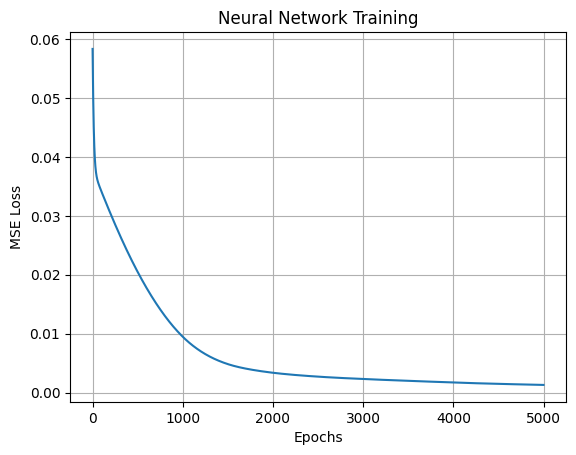

In [29]:
plt.plot(loss_history)
plt.xlabel("Epochs")
plt.ylabel("MSE Loss")
plt.title("Neural Network Training")
plt.grid()
plt.show()

### testing multiplication

In [30]:
test_inputs = np.array([
    [7, 9],
    [2, 3],
    [5, 6]
]) / 10

predictions, _ = forward_propagation(test_inputs, parameters)

print("Predicted:", predictions.flatten() * 100)
print("Actual:", [63, 6, 30])

Predicted: [60.34429279  4.36822577 36.05843505]
Actual: [63, 6, 30]


## NN with other Optimizers

Now, we'll see how other optimizes work and how each contribute!!
we'll be considering SGD(Sochastic Gradient Descent), SGD with momentum, RMSProp(Root Mean Square Propagation), Adam(Adaptive movement Estimation)

In [31]:
np.random.seed(42)

X = np.random.uniform(0, 10, (1000, 2))
y = (X[:, 0] * X[:, 1]).reshape(-1, 1)

X, y = X / 10, y / 100

X_train, X_test = X[:800], X[800:]
y_train, y_test = y[:800], y[800:]

parameters = {
    "W1": np.random.randn(2, 16) * np.sqrt(2/2),
    "b1": np.zeros((1, 16)),
    "W2": np.random.randn(16, 8) * np.sqrt(2/16),
    "b2": np.zeros((1, 8)),
    "W3": np.random.randn(8, 4) * np.sqrt(2/8),
    "b3": np.zeros((1, 4)),
    "W4": np.random.randn(4, 1) * np.sqrt(1/4),
    "b4": np.zeros((1, 1))
}

# real original params are saved
initial_parameters = {
    k: v.copy() for k, v in parameters.items()
}

print("Original initialization preserved!")

Original initialization preserved!


All optimizer''s Alogorithm

### 1. Stochastic Gradient Descent (SGD)

SGD updates parameters in the opposite direction of the calculated gradient.

$$
\theta_t = \theta_{t-1} - \eta \nabla_\theta L
$$

Where:

θ = Model parameters (weights and biases)

η = Learning rate

∇L = Gradient of the loss

how?

- Calculate gradients through backpropagation.

- Multiply gradients by the learning rate.

- Subtract the result from the current parameters.

Limitation: SGD can converge slowly and oscillate when gradients vary significantly across directions.

In [36]:
def sgd(params, grads, lr):

    for layer in range(1, 5):
        for p in ["W", "b"]:
            key = f"{p}{layer}"
            params[key] -= lr * grads[f"d{key}"]

    return params

### 2. SGD with Momentum

Momentum uses accumulated gradients from previous updates to influence the current update.

$$
v_t = \beta v_{t-1} + \nabla_\theta L
$$

$$
\theta_t = \theta_{t-1} - \eta v_t
$$

Where:

v = Accumulated gradient (velocity)

β = Momentum coefficient (typically 0.9)

η = Learning rate

how?

- Maintain a velocity for each parameter.

- Accumulate a fraction of the previous velocity.

- Add the current gradient.

- Update parameters using the accumulated velocity.

Advantage: Accelerates learning in consistent gradient directions and reduces oscillations.

In [37]:
def momentum(params, grads, state, lr, beta=0.9):

    for layer in range(1, 5):
        for p in ["W", "b"]:
            key = f"{p}{layer}"
            g = grads[f"d{key}"]

            state[key] = beta * state[key] + g
            params[key] -= lr * state[key]

    return params, state

### 3. RMSProp (Root Mean Square Propagation)

RMSProp adapts the learning rate for each parameter based on the moving average of squared gradients.

$$
s_t = \beta s_{t-1} + (1-\beta)g_t^2
$$

$$
\theta_t = \theta_{t-1} -
\frac{\eta}{\sqrt{s_t}+\epsilon}g_t
$$

Where:

s = Moving average of squared gradients

g = Current gradient

β = Decay coefficient (typically 0.9)

ε = Small constant for numerical stability

how?

- Calculate the squared gradient.

- Maintain its exponentially weighted moving average.

- Divide the gradient by the square root of this average.

- Update the parameter.

Advantage: Adapts learning rates individually for different parameters.

In [38]:
def rmsprop(params, grads, state, lr, beta=0.9, epsilon=1e-8):

    for layer in range(1, 5):
        for p in ["W", "b"]:
            key = f"{p}{layer}"
            g = grads[f"d{key}"]

            state[key] = beta * state[key] + (1-beta) * g**2

            params[key] -= lr * g / (
                np.sqrt(state[key]) + epsilon
            )

    return params, state

### 4. Adam (Adaptive Moment Estimation)

Adam combines the ideas of Momentum and RMSProp by maintaining two moving averages:

- First moment: Moving average of gradients.

$$
m_t = \beta_1m_{t-1}+(1-\beta_1)g_t
$$

- Second moment: Moving average of squared gradients.

$$
v_t = \beta_2v_{t-1}+(1-\beta_2)g_t^2
$$

Bias correction:

$$
\hat m_t = \frac{m_t}{1-\beta_1^t}
$$

$$
\hat v_t = \frac{v_t}{1-\beta_2^t}
$$

Parameter update:

$$
\theta_t = \theta_{t-1} -
\frac{\eta}{\sqrt{\hat v_t}+\epsilon}\hat m_t
$$

Where:

m = First moment estimate.

v = Second moment estimate.

β₁ = First moment decay (typically 0.9).

β₂ = Second moment decay (typically 0.999).

t = Current optimization step.

ε = Numerical stability constant.

Advantage: Combines momentum-based updates with adaptive learning rates and bias correction.

In [39]:
def adam(params, grads, state, lr, t,
         beta1=0.9, beta2=0.999, epsilon=1e-8):

    for layer in range(1, 5):
        for p in ["W", "b"]:
            key = f"{p}{layer}"
            g = grads[f"d{key}"]

            state["m_"+key] = (
                beta1 * state["m_"+key] + (1-beta1) * g
            )

            state["v_"+key] = (
                beta2 * state["v_"+key] + (1-beta2) * g**2
            )

            m_hat = state["m_"+key] / (1-beta1**t)
            v_hat = state["v_"+key] / (1-beta2**t)

            params[key] -= lr * m_hat / (
                np.sqrt(v_hat) + epsilon
            )

    return params, state

In [45]:
# algo name and their learning rate
optimizer_configs = {
    "SGD": {
        "function": sgd,
        "lr": 0.01
    },
    "Momentum": {
        "function": momentum,
        "lr": 0.01
    },
    "RMSProp": {
        "function": rmsprop,
        "lr": 0.001
    },
    "Adam": {
        "function": adam,
        "lr": 0.001
    }
}

In [49]:
results = {}

epochs = 5000

for name, lr in optimizers.items():

    params = {
        k: v.copy() for k, v in initial_parameters.items()
    }

    state = {}

    if name == "Momentum":
        state = {k: np.zeros_like(v) for k, v in params.items()}

    elif name == "RMSProp":
        state = {k: np.zeros_like(v) for k, v in params.items()}

    elif name == "Adam":
        state = {
            "m_"+k: np.zeros_like(v) for k, v in params.items()
        }
        state.update({
            "v_"+k: np.zeros_like(v) for k, v in params.items()
        })

    history = []

    for epoch in range(1, epochs + 1):

        predictions, cache = forward_propagation(X_train, params)

        loss = mse_loss(y_train, predictions)
        history.append(loss)

        grads = backpropagation(X_train, y_train, params, cache)

        if name == "SGD":
            params = sgd(params, grads, lr)

        elif name == "Momentum":
            params, state = momentum(params, grads, state, lr)

        elif name == "RMSProp":
            params, state = rmsprop(params, grads, state, lr)

        elif name == "Adam":
            params, state = adam(params, grads, state, lr, epoch)

    results[name] = {
        "loss": history,
        "parameters": params
    }

    print(f"{name}: Final loss = {history[-1]:.6f}")

SGD: Final loss = 0.000796
Momentum: Final loss = 0.000119
RMSProp: Final loss = 0.000083
Adam: Final loss = 0.000030


### Visualizing loss with all optimizer's NN

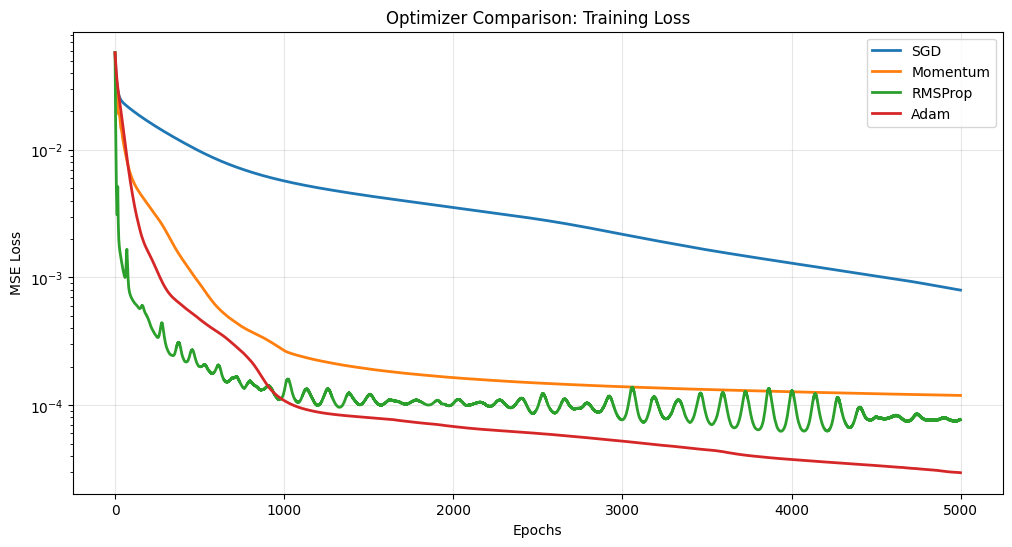

In [44]:
plt.figure(figsize=(12, 6))

for name, result in results.items():
    plt.plot(
        result["loss"],
        label=name,
        linewidth=2
    )

plt.xlabel("Epochs")
plt.ylabel("MSE Loss")
plt.title("Optimizer Comparison: Training Loss")
plt.legend()
plt.grid(alpha=0.3)
plt.yscale("log")
plt.show()

In [50]:
print("OPTIMIZER PERFORMANCE")
print("-" * 45)

for name, result in results.items():

    params = result["parameters"]

    train_pred, _ = forward_propagation(X_train, params)
    test_pred, _ = forward_propagation(X_test, params)

    train_loss = mse_loss(y_train, train_pred)
    test_loss = mse_loss(y_test, test_pred)

    print(f"\n{name}")
    print(f"Training MSE: {train_loss:.6f}")
    print(f"Testing MSE:  {test_loss:.6f}")

OPTIMIZER PERFORMANCE
---------------------------------------------

SGD
Training MSE: 0.000796
Testing MSE:  0.000706

Momentum
Training MSE: 0.000119
Testing MSE:  0.000125

RMSProp
Training MSE: 0.000084
Testing MSE:  0.000086

Adam
Training MSE: 0.000029
Testing MSE:  0.000031
